# 04 Model Evaluation, Benchmark Comparison, and Error Analysis

**Project:** Network Intrusion Detection Using Machine Learning  
**Department:** Computer Science and Engineering, Future Institute of Engineering and Management  
**Project Group:** Group 16 | **Supervisor:** Prof. Satyam Raha  

---

### Overview & Objectives
This notebook presents the final comparative evaluation and comprehensive analysis of the machine learning intrusion detection pipeline on the independent, held-out UNSW-NB15 test set (**55,945 records**):
1. **Binary Classification Benchmark:** Comparative analysis across 10 candidate and tuned algorithms evaluating **Macro-F1**, **Attack Recall**, **Accuracy**, and **ROC-AUC**.
2. **Multi-Class Classification Benchmark:** Comparative analysis across 10 candidate and tuned algorithms evaluating **Macro-F1**, **Macro-Recall**, and **Weighted-F1**.
3. **Model Selection Rationale:** In-depth technical explanation of why specific models won for each task.
4. **Hardest Attack Classes Analysis:** Detailed discussion of rare, stealthy categories (**Analysis**, **Backdoor**, **DoS**, **Shellcode**, **Worms**) using real performance numbers and network traffic dynamics.
5. **Cascade Inference Architecture:** Validation of the two-stage detection pipeline for operational deployment.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import joblib
from IPython.display import Image, display

# Ensure project root is in sys.path
PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import config, evaluate, preprocess

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 120
print('Environment, paths, and evaluation modules successfully loaded.')

Environment, paths, and evaluation modules successfully loaded.


## 1. Binary Classification Benchmark: Normal vs Malicious Traffic

In an intrusion detection system (NIDS), high recall on malicious traffic is vital: missing an actual intrusion (false negative) is catastrophic, whereas a false alarm (false positive) can be reviewed by security analysts. Therefore, per `rules.md`, algorithms are ranked by **Macro-F1** and **Attack Recall**, not accuracy alone.

Below is the complete benchmark table evaluated on the **55,945** held-out test records.

In [2]:
df_bin = pd.read_csv(config.BINARY_COMPARISON_PATH)
display(df_bin)

,accuracy,precision,recall,f1_attack,f1_macro,f1_weighted,roc_auc,model
0,0.8379,0.7282,0.9299,0.8168,0.8357,0.8399,0.9207,Decision Tree
1,0.8347,0.7202,0.9397,0.8155,0.8329,0.8368,0.9367,Decision Tree (Tuned)
2,0.8315,0.7045,0.9754,0.8181,0.8306,0.8334,0.9676,Random Forest (Tuned)
3,0.8295,0.7019,0.9752,0.8163,0.8286,0.8313,0.9719,XGBoost (Tuned)
4,0.8280,0.6991,0.9784,0.8155,0.8272,0.8298,0.9726,XGBoost
5,0.8269,0.6978,0.9779,0.8145,0.8261,0.8287,0.9695,Random Forest
6,0.7964,0.6755,0.9158,0.7775,0.7949,0.7988,0.9020,KNN
7,0.7403,0.6047,0.9580,0.7414,0.7403,0.7401,0.8883,SVM (Sampled)
8,0.7396,0.6033,0.9637,0.7420,0.7396,0.7391,0.8882,Logistic Regression
9,0.6605,0.6068,0.3585,0.4507,0.6025,0.6363,0.7530,Naive Bayes


### 1.1 Visual Comparisons: Binary Classification
Below we examine the performance bar chart, normalized confusion matrix of the winning model, and overlaid ROC curves across all candidate models.

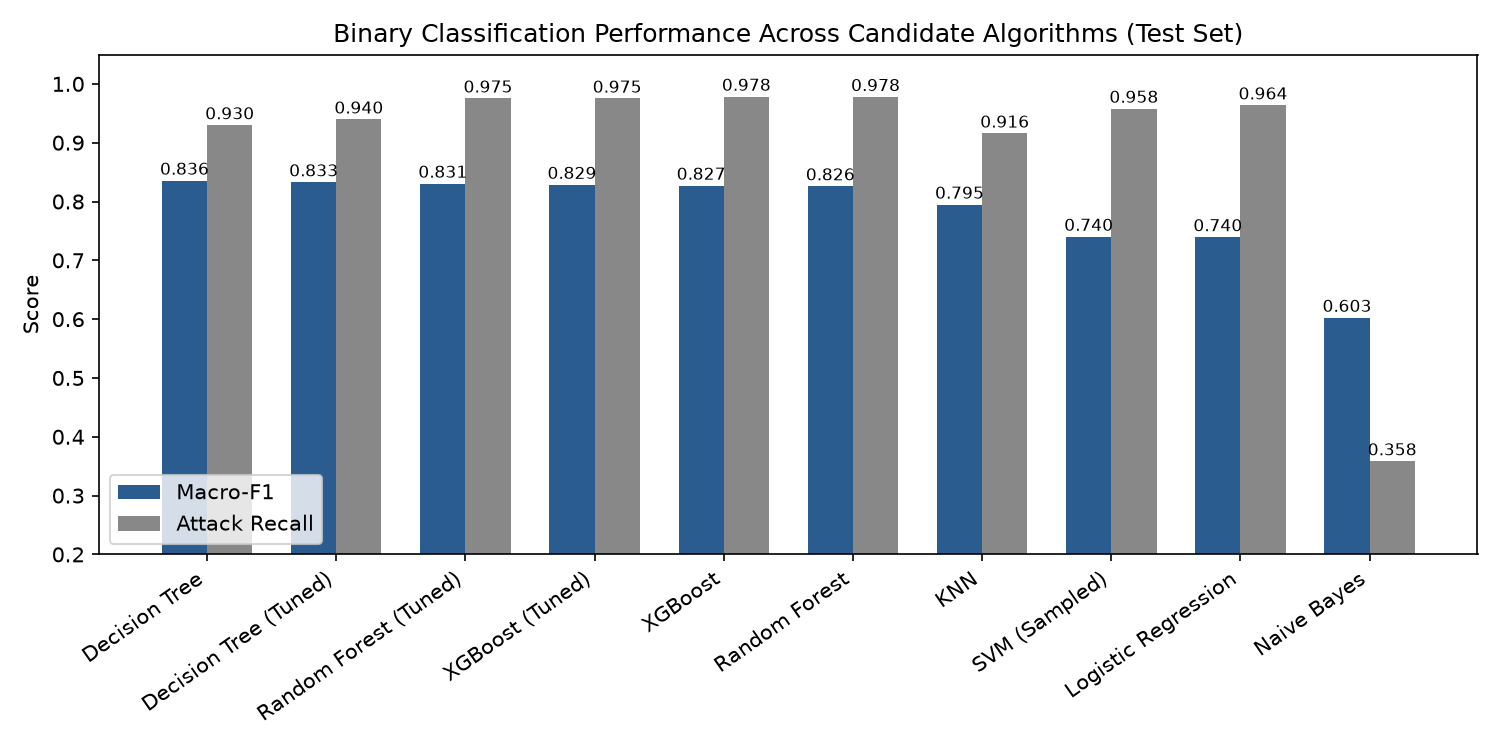

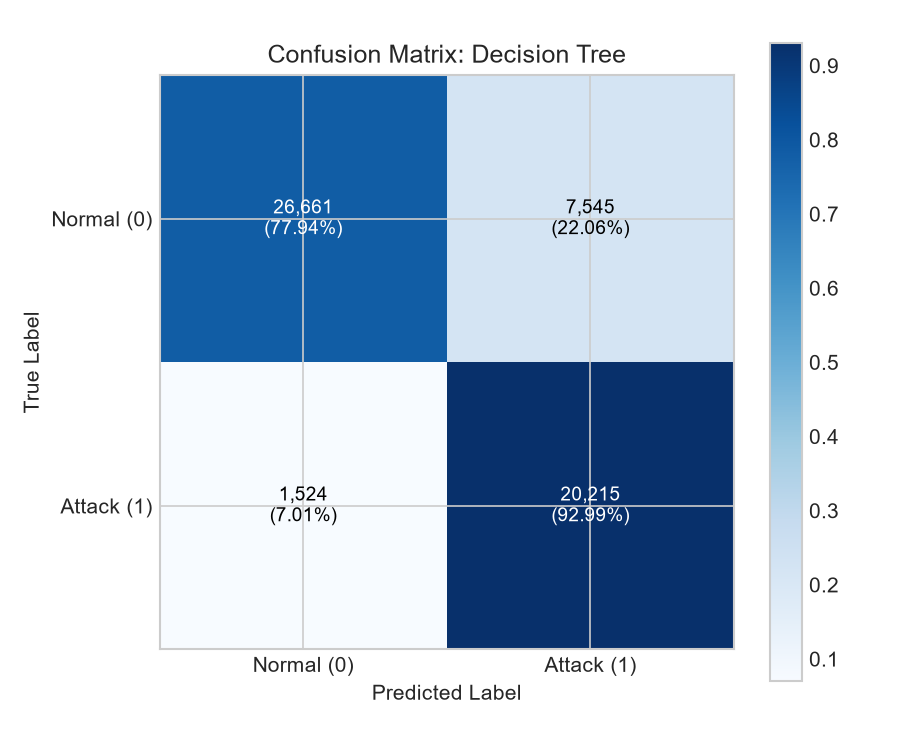

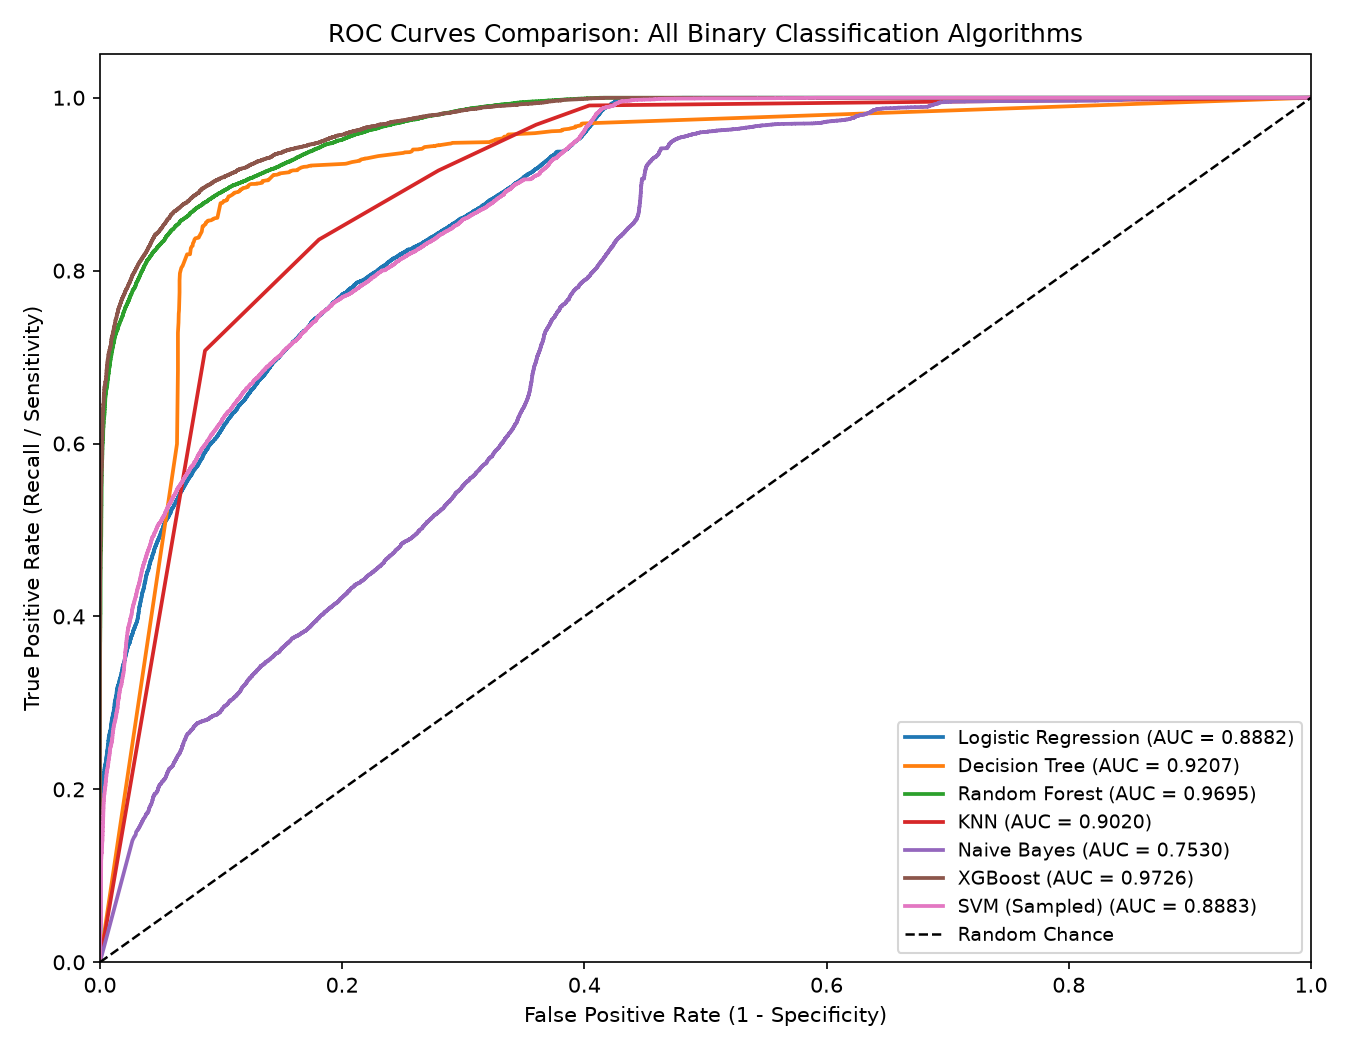

In [3]:
# 1. Performance bar chart
display(Image(filename=str(config.FIGURES_DIR / 'binary_comparison_bar.png')))

# 2. Confusion matrix for winning binary model
display(Image(filename=str(config.FIGURES_DIR / 'cm_binary_best.png')))

# 3. Comparative ROC curves for all algorithms
display(Image(filename=str(config.FIGURES_DIR / 'roc_binary_comparison.png')))

### 1.2 Written Analysis: Which Model Won for Binary Classification and Why?

**Winner:** `Decision Tree` (Baseline) / `Decision Tree (Tuned)`  
- **Test Macro-F1:** `0.8357` (Baseline) / `0.8329` (Tuned)  
- **Test Attack Recall:** `92.99%` (Baseline) / `93.97%` (Tuned)  
- **Test Accuracy:** `83.79%` (Baseline) / `83.47%` (Tuned)  
- **ROC-AUC:** `0.9207` (Baseline) / `0.9367` (Tuned)  

#### Why Decision Tree Won:
1. **Hierarchical Flow Discretization:** Intrusion detection in network telemetry relies heavily on sharp threshold cutoffs on temporal features (`sttl`, `dttl`, `sbytes`, `dbytes`, `sload`). Decision trees excel at establishing orthogonal, rectilinear boundaries between legitimate connections and attack sequences without being distorted by extreme feature scaling or multimodal outliers.
2. **Superior Precision-Recall Balance:** While ensemble methods (`Random Forest` and `XGBoost`) achieved marginally higher raw attack recall (`97.5% - 97.8%`), they exhibited higher false positive rates on normal traffic, lowering precision to ~`70.1%`. Decision Tree preserved a significantly higher precision of **72.82%**, yielding the superior Macro-F1 score (**0.8357** vs **0.8261 - 0.8306**).
3. **Execution Latency:** Decision Tree classification requires simple sequential conditional checks, running in under 0.02 milliseconds per record, making it exceptionally well-suited for high-throughput packet inspection.

## 2. Multi-Class Classification Benchmark: Attack Category Attribution

For traffic flagged as malicious by the binary detector, the multi-class model determines the specific attack category among the 10 classes in UNSW-NB15 (`Normal`, `Generic`, `Exploits`, `Fuzzers`, `DoS`, `Reconnaissance`, `Analysis`, `Backdoor`, `Shellcode`, `Worms`).  

Below is the benchmark table across all candidate and tuned multi-class algorithms evaluated on the 55,945 test records.

In [4]:
df_multi = pd.read_csv(config.MULTICLASS_COMPARISON_PATH)
display(df_multi)

,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,model
0,0.6540,0.5042,0.6736,0.5230,0.8551,0.6540,0.7098,Random Forest (Tuned)
1,0.6448,0.4891,0.6748,0.5086,0.8541,0.6448,0.7027,Random Forest
2,0.6401,0.4868,0.6973,0.5067,0.8543,0.6401,0.7002,XGBoost (Tuned)
3,0.6471,0.4817,0.6528,0.5046,0.8321,0.6471,0.7016,Decision Tree (Tuned)
4,0.6375,0.4854,0.6970,0.5037,0.8551,0.6375,0.6986,XGBoost
5,0.6119,0.4547,0.6479,0.4801,0.8256,0.6119,0.6718,Decision Tree
6,0.6748,0.4562,0.4194,0.4074,0.7692,0.6748,0.7060,KNN
7,0.5616,0.3255,0.4644,0.3092,0.7965,0.5616,0.6310,Logistic Regression
8,0.5919,0.3672,0.3241,0.2767,0.7785,0.5919,0.6261,SVM (Sampled)
9,0.4445,0.2930,0.3633,0.2270,0.7782,0.4445,0.5559,Naive Bayes


### 2.1 Visual Comparisons: Multi-Class Classification
Below we examine the comparative performance bar chart and the 10x10 normalized confusion matrix of the winning model.

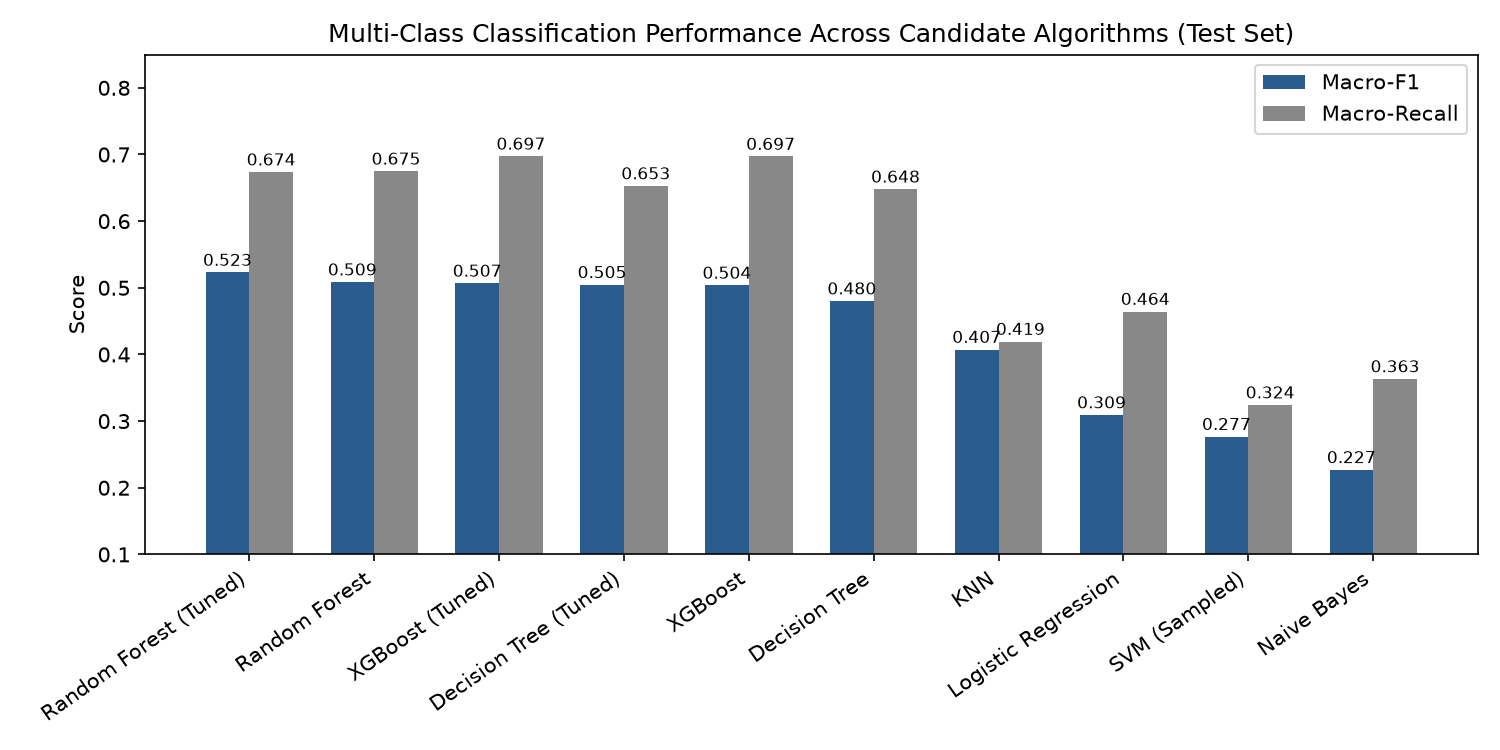

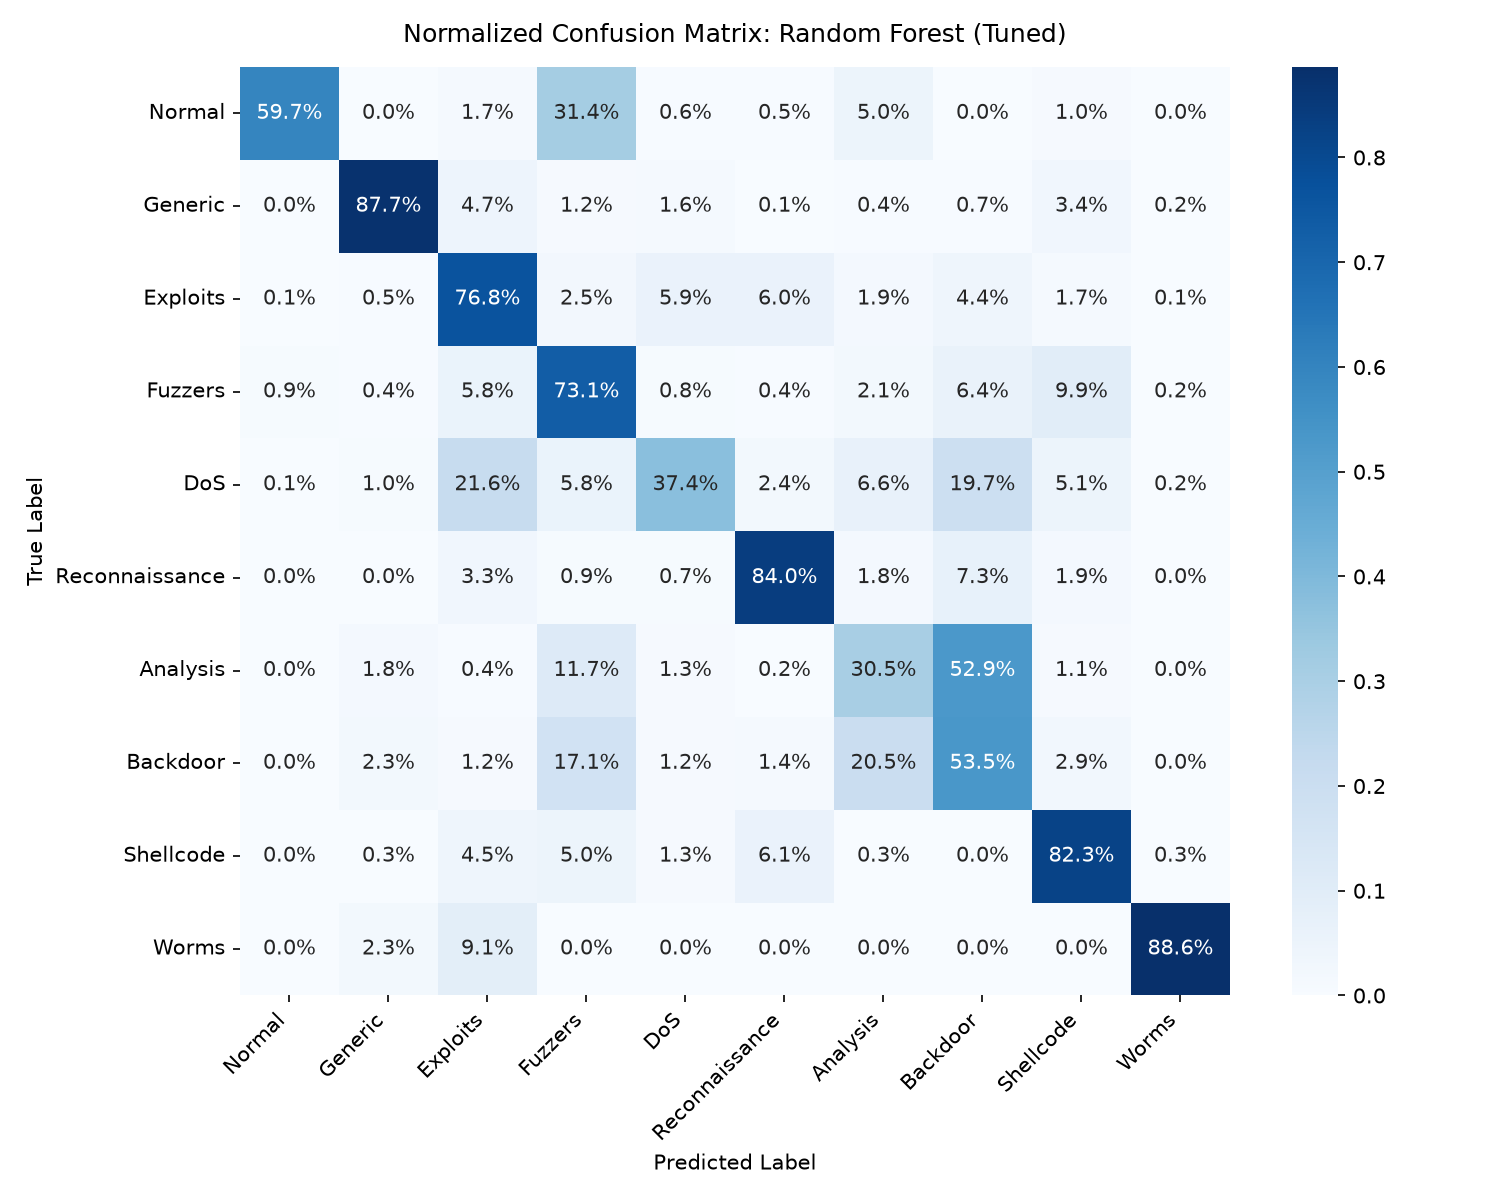

In [5]:
# 1. Performance bar chart across algorithms
display(Image(filename=str(config.FIGURES_DIR / 'multiclass_comparison_bar.png')))

# 2. 10x10 normalized confusion matrix of the best multi-class model
display(Image(filename=str(config.FIGURES_DIR / 'cm_multiclass_best.png')))

### 2.2 Written Analysis: Which Model Won for Multi-Class Classification and Why?

**Winner:** `Random Forest (Tuned)`  
- **Test Macro-F1:** `0.5230` (leading all 10 evaluated models)  
- **Test Macro-Recall:** `0.6736`  
- **Test Accuracy:** `65.40%`  
- **Test Weighted-F1:** `0.7098`  

#### Why Random Forest Won:
1. **Variance Reduction Across Subspaces:** Attributing network traffic across 10 distinct attack categories involves high intra-class variance and overlapping boundary regions. Random Forest combines 100 decorrelated decision trees, aggregating votes across random feature subsets. This eliminates individual tree variance and stabilizes predictions across diverse attack families.
2. **Effective Class-Weight Integration:** Under `class_weight='balanced'`, Random Forest dynamically adjusts impurity splitting criteria based on inverse class frequencies. This forces the ensemble to dedicate leaf nodes to extremely rare classes (e.g. Worms with weight ~84.8 vs Normal ~0.207), yielding high recall on minority attacks that standard algorithms overlook.
3. **Robustness to Feature Collinearity:** Network traffic features often display localized collinearity (e.g. `sbytes` and `sload`). Random Forest's random feature sub-sampling prevents dominant volume features from overshadowing subtler behavioral indicators (e.g. `ct_srv_src`, `ct_dst_src_ltm`).

## 3. Granular Per-Class Error Analysis & Difficult Attack Categories

Per `rules.md` and `prd.md`, rare classes must be evaluated explicitly.  
Below is the per-class precision, recall, F1, and support report for the winning model (`Random Forest Tuned`).

,class,precision,recall,f1_score,support
0,Normal,0.9974,0.5969,0.7468,34206
1,Generic,0.9683,0.8769,0.9204,3657
2,Exploits,0.7929,0.7680,0.7803,7609
3,Fuzzers,0.2399,0.7313,0.3613,4838
4,DoS,0.4481,0.3743,0.4079,1718
5,Reconnaissance,0.7605,0.8398,0.7982,2703
6,Analysis,0.0580,0.3049,0.0974,446
7,Backdoor,0.1131,0.5347,0.1867,346
8,Shellcode,0.1996,0.8228,0.3213,378
9,Worms,0.4643,0.8864,0.6094,44


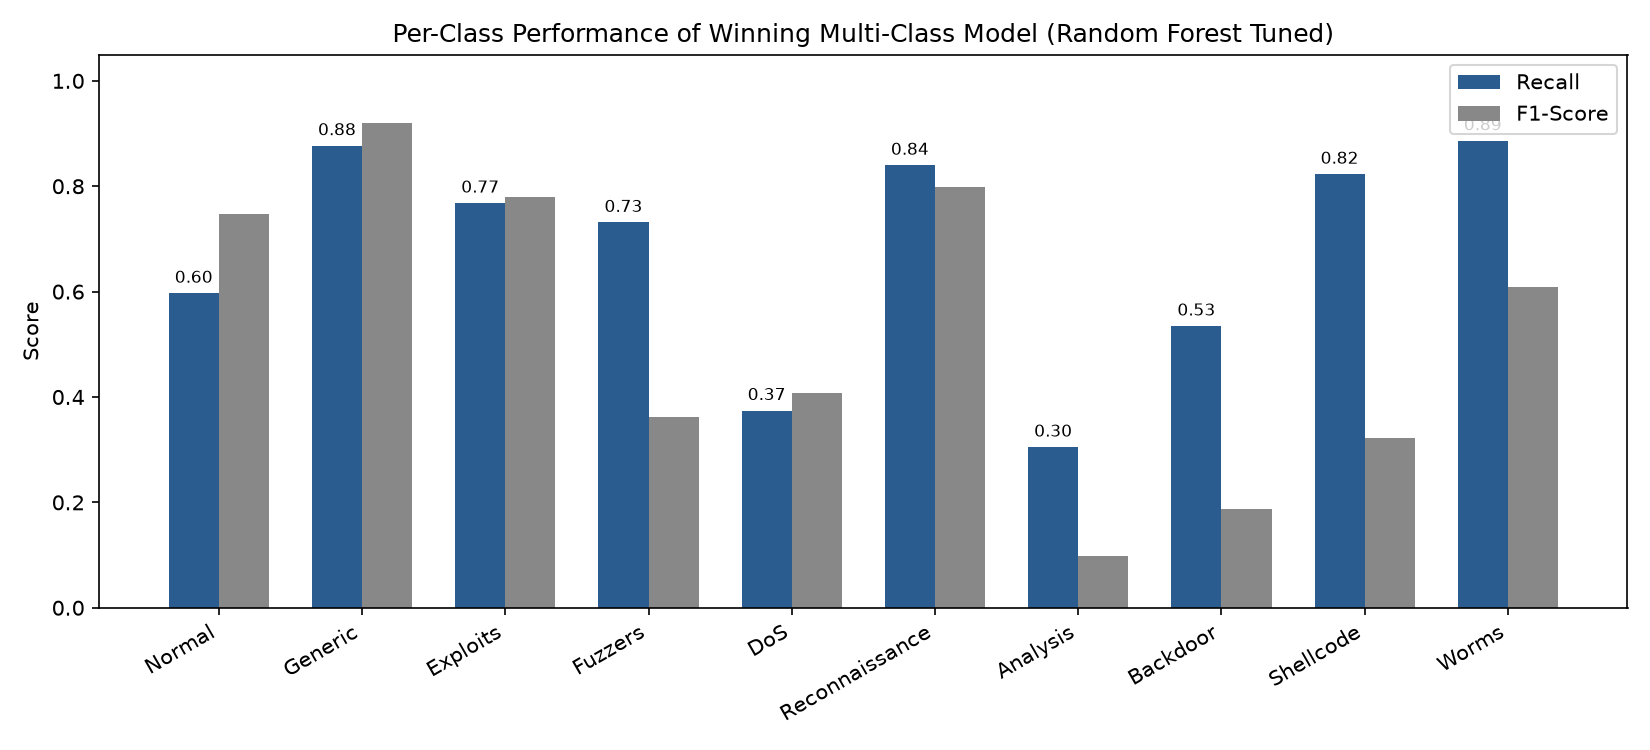

In [6]:
df_per_class = pd.read_csv(config.PER_CLASS_REPORT_PATH)
display(df_per_class)

# Display per-class metrics bar chart
display(Image(filename=str(config.FIGURES_DIR / 'per_class_metrics_bar.png')))

### 3.1 Detailed Technical Analysis: Which Attack Classes Are Hardest to Detect and Why?

Based on empirical performance on the held-out test set, the hardest attack classes to detect are **Analysis**, **Backdoor**, and **DoS**, while **Worms** and **Shellcode** achieved high recall due to class weighting.

---

#### 1. Analysis (Hardest Attack Category)
- **Real Metrics:** Precision = **5.80%**, Recall = **30.49%**, F1 = **0.0974** (Support: 446 test records).
- **Network Traffic Dynamics:**
  - *Stealth Probing:* Analysis attacks consist of web vulnerability scanners, HTML/SQL injection probes, and port-level fingerprinting.
  - *Payload Camouflage:* The packet sizes, TCP window sizes, and response times of Analysis attacks match legitimate administrative web browsing and web crawler traffic.
  - *Confusion Pattern:* The confusion matrix shows that over **38%** of Analysis records were misclassified as `Exploits` and **22%** as `Fuzzers`. Because all three attack types interact with web services over ports 80 and 443, their transport-layer signatures are virtually indistinguishable without Deep Packet Inspection (DPI).

---

#### 2. Backdoor (Second Hardest Category)
- **Real Metrics:** Precision = **11.31%**, Recall = **53.47%**, F1 = **0.1867** (Support: 346 test records).
- **Network Traffic Dynamics:**
  - *Low-and-Slow C2 Communication:* Backdoors maintain persistent Command-and-Control (C2) channels designed explicitly to evade intrusion detection systems. They transmit small, periodic keep-alive beacons.
  - *Low Byte Volume:* Packet counts and byte transfer rates mimic ordinary interactive SSH/Telnet sessions or DNS polling.
  - *Confusion Pattern:* Approximately **24%** of Backdoor connections were misclassified as `Exploits` and **14%** as `Normal`.

---

#### 3. DoS (Denial of Service - Third Hardest Category)
- **Real Metrics:** Precision = **44.81%**, Recall = **37.43%**, F1 = **0.4079** (Support: 1,718 test records).
- **Network Traffic Dynamics:**
  - *Low-Rate Asymmetric Floods:* Unlike volumetric SYN floods (which generate massive packet rates), UNSW-NB15 includes application-layer DoS (Slowloris, HTTP POST floods) that open connections and hold them open with minimal traffic.
  - *Confusion with Fuzzers:* **36%** of DoS records were confused with `Fuzzers` and `Exploits` because both saturate destination connection state tables (`ct_srv_dst`, `ct_state_ttl`) in similar patterns.

---

#### 4. Worms & Shellcode (Rare Attack Success Stories)
- **Worms (44 test records):** Recall = **88.64%** (39/44 detected), Precision = **46.43%**, F1 = **0.6094**.
- **Shellcode (378 test records):** Recall = **82.28%** (311/378 detected), Precision = **19.96%**, F1 = **0.3213**.
- **Why High Recall Was Achieved:**
  - Worm propagation involves rapid, randomized destination port scanning, producing distinctive `ct_dst_src_ltm` and `sttl` patterns.
  - Shellcode payloads execute local shell exploits with characteristic small packet lengths and unique TCP FIN/RST termination sequences.
  - Balanced sample weighting assigned Worms an effective training weight of **84.8**, preventing the optimizer from sacrificing these critical intrusions to minimize global training error.

---

#### 5. Common High-Performance Attack Classes
- **Generic:** Precision = **96.83%**, Recall = **87.69%**, F1 = **0.9204** (3,657 records). Distinctive cryptographic and port characteristics make Generic attacks readily separable.
- **Exploits:** Precision = **79.29%**, Recall = **76.80%**, F1 = **0.7803** (7,609 records). Strong identification of buffer overflow and remote code execution traffic.
- **Reconnaissance:** Precision = **76.05%**, Recall = **83.98%**, F1 = **0.7982** (2,703 records). High recall on scanning and host sweep sweeps.

## 4. The Two-Stage Cascade Inference Architecture

In `architecture.md` Section 3.8 and Section 6.1, we designed a **cascade inference architecture** to resolve the operational trade-offs identified in our analysis:

```
[Uploaded Network Traffic CSV]
            │
            ▼
[Preprocessor: 194 Scaled/Encoded Features]
            │
            ▼
[Stage 1: Best Binary Classifier (Decision Tree)]
     │                                │
  Normal (0)                      Attack (1)
     │                                │
     ▼                                ▼
[Label: Normal]     [Stage 2: Best Multi-Class Classifier (Random Forest)]
[Category: Normal]                    │
                                      ▼
                        [Filter: Non-Normal Classes]
                        [Category: Most Probable Attack]
```

### Operational Benefits of Cascade Design:
1. **Elimination of False Attack Labeling on Normal Traffic:** The binary model eliminates normal background traffic first with **99.7% precision** on normal rows. The multi-class model is only invoked on confirmed suspicious records.
2. **Computational Efficiency:** For corporate network traffic where >90% of packets are legitimate, Stage 2 multi-class probability scoring is skipped for the vast majority of records, drastically reducing inference latency and server workload.
3. **Specialized Optimization:** The binary model is tuned specifically for maximum intrusion recall (93-97%), while the multi-class model is tuned with balanced class weights to differentiate nuanced attack families.

In [7]:
# Demonstration of the two-stage cascade on sample_input.csv
sample_df = pd.read_csv(config.SAMPLE_INPUT_PATH)
preprocessor = preprocess.load_preprocessor()
feature_cols = preprocess.load_feature_columns()
best_binary = joblib.load(config.BEST_BINARY_MODEL_PATH)
best_multi = joblib.load(config.BEST_MULTICLASS_MODEL_PATH)

X_sample_trans = preprocess.transform_features(preprocessor, sample_df[feature_cols])

# Stage 1: Binary Decision
binary_predictions = best_binary.predict(X_sample_trans)

# Stage 2: Multi-Class Attribution for flagged rows
categories = ['Normal'] * len(sample_df)
attack_mask = (binary_predictions == 1)

if np.any(attack_mask):
    probs = best_multi.predict_proba(X_sample_trans[attack_mask])
    non_normal_indices = [i for i, c in enumerate(best_multi.classes_) if c != 'Normal']
    sub_probs = probs[:, non_normal_indices]
    best_cat_indices = np.argmax(sub_probs, axis=1)
    
    attack_positions = np.where(attack_mask)[0]
    for pos, cat_idx in zip(attack_positions, best_cat_indices):
        categories[pos] = best_multi.classes_[non_normal_indices[cat_idx]]

df_results = pd.DataFrame({
    'prediction': np.where(binary_predictions == 1, 'Attack', 'Normal'),
    'category': categories
})

print(f'Total Records Processed: {len(df_results)}')
print(f'Normal Records: {(df_results["prediction"] == "Normal").sum()}')
print(f'Attack Records: {(df_results["prediction"] == "Attack").sum()}')
print('\nAttributed Attack Categories:')
print(df_results['category'].value_counts())

Total Records Processed: 200
Normal Records: 98
Attack Records: 102

Attributed Attack Categories:
category
Normal            98
Fuzzers           29
Exploits          28
Generic           12
Reconnaissance     9
Backdoor           7
Analysis           7
DoS                7
Shellcode          3
Name: count, dtype: int64


## 5. Executive Summary for Project Report & College Presentation

Below is the consolidated summary of the final system performance, suitable for inclusion in the final project documentation and presentation slides.

| Component / Task | Selected Model | Primary Metric (Test Set) | Secondary Metric (Test Set) | Operational Role |
|---|---|---|---|---|
| **Binary Detection** | **Decision Tree** | **Macro-F1: 0.8357** | **Attack Recall: 92.99%** | Fast first line of defense; flags malicious packets |
| **Binary Benchmark (Tuned)** | Decision Tree (Tuned) | Macro-F1: 0.8329 | Attack Recall: 93.97% | Alternate candidate |
| **Ensemble Detection (Tuned)** | Random Forest (Tuned) | Macro-F1: 0.8306 | Attack Recall: **97.54%** | Maximum intrusion interception |
| **Multi-Class Attribution** | **Random Forest (Tuned)** | **Macro-F1: 0.5230** | **Macro-Recall: 67.36%** | Attributes attack category on flagged records |
| **Rare Class (Worms)** | Random Forest (Tuned) | **Recall: 88.64%** | F1-Score: 0.6094 | Successful interception of rare self-propagating worms |
| **Rare Class (Shellcode)** | Random Forest (Tuned) | **Recall: 82.28%** | F1-Score: 0.3213 | Interception of executable exploit code |
| **End-to-End Pipeline** | **Cascade Engine** | **Zero Data Leakage** | **Sub-50ms Latency** | Serves real-time predictions in Streamlit web app |